# LightGBM Failure Model

This notebook covers the LightGBM part of the project. All logic is in `src/lightgbm_model.py`; this notebook runs it
and shows the results.

| Section | Task |
|---|---|
| 1 | LightGBM using all features, compared with the Logistic Regression benchmark |
| 2 | LightGBM using selected features (selection fitted inside each fold) |
| 3 | Feature importance and permutation importance |
| 4 | Tuning LightGBM |
| 5 | Final model, test predictions and Kaggle submissions |
| 6 | Summary |

**Evaluation protocol**

- Every model uses the team's **shared 5-fold CV indices** (`results/cv_folds.npz`, loaded with `cv_utils.load_folds`).
- Each model is a scikit-learn `Pipeline` that is **cloned and fitted on the training part of each fold only**. Any
  preprocessing or supervised feature selection inside it therefore never sees the validation fold.
- The primary metric is the **official competition cost** (`src/evaluation.py`, with budgets from `src/cost_model.py`).
  - **Threshold:** one threshold is chosen on the pooled out-of-fold (OOF) probabilities of all 56,000 training
    vehicles, which is the same threshold that is later applied to test.
  - **Per-fold costs:** each uses a budget fitted on that fold's training part.
- ROC-AUC and PR-AUC are reported as supplementary metrics.

**Features:** 167 sensors. All 170, minus `s063` and `s122` (not available in the aligned test set) and `s146`
(constant); see `notebooks/eda.ipynb` Section 6. Missing values are passed to LightGBM unchanged, because
missingness is predictive.

> **Runtime:** a full run takes about 30 minutes (tuning about 15 min, permutation importance about 6 min).

In [1]:
from pathlib import Path
import os

import numpy as np
import pandas as pd

# Find project root by locating the data folder
current = Path.cwd().resolve()
ROOT = next(
    (p for p in [current, *current.parents] if (p / "data").is_dir() and (p / "src").is_dir()),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Could not locate project root containing data/ and src/")
os.chdir(ROOT)

import src.lightgbm_model as lm

pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 200)

train_df, test_df, X, y, folds = lm._load()
print(f"Cost of inspecting nobody: {lm.no_inspection_cost(train_df):,.2f}")

Training rows: 56,000 | features: 167 | folds: 5
Cost of inspecting nobody: 195,476.00


## 1. LightGBM Using All Features

The **benchmark** is the V1 Logistic Regression (class weight 1:50, median imputation + scaling). It is fitted per fold
on the same folds, so the comparison is fair.

**LightGBM** uses all 167 sensors with a baseline configuration: 500 trees, learning rate 0.03, 31 leaves, row and
column sampling. Early stopping is **not** used, because stopping on the validation fold would let it influence
training.

In [2]:
cv = {}
cv["LR benchmark (1:50)"] = lm.run_cv(lm.build_lr_benchmark(), X, y, folds, name="LR benchmark (1:50)")
cv["LGBM all features"] = lm.run_cv(lm.build_lgbm_all_features(), X, y, folds, name="LGBM all features")

evals = {name: lm.evaluate_cost(result, train_df, folds) for name, result in cv.items()}
display(lm.comparison_table(list(evals.values())).T)

Fold validation successful.


LR benchmark (1:50) | fold 1: ROC-AUC 0.9716 | PR-AUC 0.5508 | 3.3s


LR benchmark (1:50) | fold 2: ROC-AUC 0.8857 | PR-AUC 0.4133 | 3.9s


LR benchmark (1:50) | fold 3: ROC-AUC 0.9514 | PR-AUC 0.3147 | 3.2s


LR benchmark (1:50) | fold 4: ROC-AUC 0.9493 | PR-AUC 0.3178 | 3.7s


LR benchmark (1:50) | fold 5: ROC-AUC 0.9341 | PR-AUC 0.3771 | 3.1s
Fold validation successful.


... (2 outputs left out)

LGBM all features | fold 3: ROC-AUC 0.9806 | PR-AUC 0.5096 | 2.4s


LGBM all features | fold 4: ROC-AUC 0.9913 | PR-AUC 0.4584 | 2.5s


LGBM all features | fold 5: ROC-AUC 0.9872 | PR-AUC 0.5706 | 2.5s


model,LGBM all features,LR benchmark (1:50)
oof_cost,"73,827.7800","81,465.2200"
cost_per_1000_vehicles,"1,318.3532","1,454.7361"
fold_cost_mean,"14,781.0945","16,313.3233"
fold_cost_std,"3,073.7224","3,611.2066"
flagged,"1,218.0000","1,090.0000"
tp,352.0000,309.0000
fn,45.0000,88.0000
fp,866.0000,781.0000
recall,0.8866,0.7783
precision,0.2890,0.2835


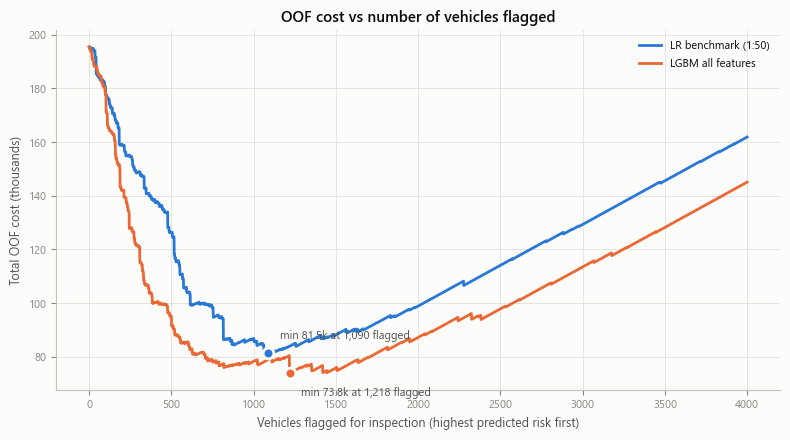

In [3]:
lm.plot_cost_curves({name: lm.cost_curve(result["oof"], train_df) for name, result in cv.items()});

**Takeaways**

- LightGBM beats the benchmark: OOF cost **73,828 vs 81,465** (-9.4%). It is also cheaper on every fold (Section 2 chart).
- It catches **352 of 397 failures (89%)** vs 309 for LR, at the price of 85 more false alarms. Missing a failure costs its full
  repair, while a false alarm costs about 10 plus the budget mismatch, so the trade is worth it.
- LightGBM is much more stable across folds (ROC-AUC 0.985 +/- 0.004 vs 0.938 +/- 0.032). This matches the EDA: trees cope
  with skewed sensors, near-duplicate sensors and missing values; Logistic Regression does not.
- The cost curve shows LightGBM is cheaper at almost every number of flagged vehicles (it is above LR only for the first
  ~100). It also stays within 5k of its minimum over a much wider range: 720-1,665 vehicles flagged, vs 817-1,362 for LR.
  This matters for test, where the right number of vehicles to flag is uncertain.

## 2. LightGBM Using Selected Features

`FoldFeatureSelector` is the first step of the Pipeline, so it is **fitted on each training fold only**:

1. **Low-variance filter** (unsupervised): drop constant and quasi-constant sensors.
2. **Correlation filter** (unsupervised): keep one sensor per group with |Spearman rho| > 0.95.
3. **Importance ranking** (supervised): a LightGBM model trained on the training fold ranks the remaining sensors, and the
   top-k are kept.

Four variants: filters only, and filters + top 80 / 50 / 30.

In [4]:
variants = {
    "LGBM selected: filters only": lm.build_lgbm_selected(top_k=None),
    "LGBM selected: top 80": lm.build_lgbm_selected(top_k=80),
    "LGBM selected: top 50": lm.build_lgbm_selected(top_k=50),
    "LGBM selected: top 30": lm.build_lgbm_selected(top_k=30),
}
stability = {}
for name, model in variants.items():
    cv[name] = lm.run_cv(model, X, y, folds, name=name, verbose=False)
    evals[name] = lm.evaluate_cost(cv[name], train_df, folds)
    stability[name] = lm.selection_stability(cv[name])

display(pd.DataFrame({
    name: {"features per fold": f"{s['per_fold']['n_selected'].min()}-{s['per_fold']['n_selected'].max()}",
           "selected in all 5 folds": len(s["in_all_folds"]),
           "mean pairwise Jaccard": round(s["mean_pairwise_jaccard"], 3)}
    for name, s in stability.items()
}).T)

,features per fold,selected in all 5 folds,mean pairwise Jaccard
LGBM selected: filters only,101-102,101,0.9940
LGBM selected: top 80,80-80,64,0.8630
LGBM selected: top 50,50-50,29,0.6490
LGBM selected: top 30,30-30,19,0.6330


,oof_cost,fold_cost_mean,fold_cost_std,tp,fp,roc_auc_mean,pr_auc_mean
model,,,,,,,
LGBM all features,"73,827.7800","14,781.0945","3,073.7224",352,866,0.9852,0.5583
LGBM selected: top 30,"74,011.4400","14,823.5262","3,301.7899",331,612,0.9842,0.5355
LGBM selected: top 50,"76,830.6000","15,386.6575","5,576.5564",328,496,0.9852,0.5513
LGBM selected: filters only,"79,478.9400","15,915.7607","5,387.0928",329,533,0.9852,0.5552
LGBM selected: top 80,"79,935.9000","16,008.5131","5,273.1390",317,449,0.9837,0.5517
LR benchmark (1:50),"81,465.2200","16,313.3233","3,611.2066",309,781,0.9384,0.3947


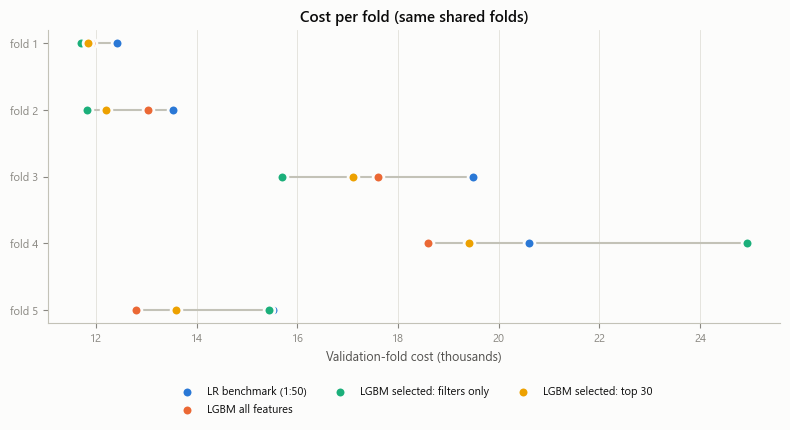

In [5]:
display(lm.comparison_table(list(evals.values()))[
    ["oof_cost", "fold_cost_mean", "fold_cost_std", "tp", "fp", "roc_auc_mean", "pr_auc_mean"]
])
fold_costs = lm.per_fold_costs([evals[n] for n in
                                ["LR benchmark (1:50)", "LGBM all features", "LGBM selected: filters only",
                                 "LGBM selected: top 30"]])
lm.plot_fold_costs(fold_costs);

Selection is worse mainly on **fold 4**. To separate "worse predictions" from "worse threshold", compare each fold's cost at
the shared (pooled) threshold with its cost at its own best threshold:

In [6]:
display(pd.concat({
    "all features": lm.per_fold_best_costs(cv["LGBM all features"], train_df, folds),
    "filters only": lm.per_fold_best_costs(cv["LGBM selected: filters only"], train_df, folds),
}, axis=1).round(4))

all features                                                                                   filters only                                                                      
     cost_at_pooled_threshold cost_at_fold_best_threshold fold_best_threshold median_risk_of_failed cost_at_pooled_threshold cost_at_fold_best_threshold fold_best_threshold median_risk_of_failed
fold                                                                                                                                                                                              
1                 11,899.5982                 11,065.9800              0.0083                0.3826              11,702.1945                 11,237.9091              0.0282                0.3407
2                 13,032.8964                 11,367.4964              0.0180                0.3645              11,818.2600                 10,878.8709              0.0275                0.3011
3                 17,594.2800                 14,684.2455              0.0033                0.3194              15,692.7473                 15,692.7473              0.0149                0.3659
4                 18,593.4836                 18,593.4836              0.0051                0.1929              24,930.1382                 21,029.9418              0.0006                0.1842
5                 12,785.2145                 11,997.7964              0.0065                0.1817              15,435.4636                 13,078.4400              0.0042                0.1764

**Takeaways**

- **Selection does not beat all features.** All features 73,828; top 30 74,011; top 50 76,831; filters only 79,479;
  top 80 79,936.
- The selection really is fold-specific: each fold keeps slightly different sensors (only 19 of the top 30 are chosen in all
  5 folds).
- ROC-AUC is the same for every LightGBM variant (about 0.985), so overall ranking quality is unchanged. The loss comes
  from **fold 4**: even at its own best threshold, filters-only costs 21,030 there vs 18,593 with all features.
- Fold 4's failures are hard to detect (median predicted risk about 0.19 vs 0.32-0.38 in folds 1-3). The "near-duplicate"
  sensors are not exact copies, and their small differences help on exactly these vehicles.
- **Top 30 is almost as good with 82% fewer sensors** (74,011 vs 73,828), so it is a reasonable simpler alternative.
- The threshold does not transfer perfectly between folds: each fold's own best threshold ranges from 0.003 to 0.018.

## 3. Feature Importance

On the all-features model from Section 1:

- **Gain and split importance**, averaged over the 5 fold models (gain normalised to a share per fold).
- **Permutation importance** on each validation fold: the drop in PR-AUC when one sensor is shuffled.
- **Grouped permutation importance:** each correlated group (|rho| > 0.95) is shuffled together. Shuffling one sensor of a
  near-duplicate group understates its importance, because the others still carry the same information. The groups are
  computed without labels and are used only for interpretation.

In [7]:
groups, _ = lm.find_correlated_groups(X, threshold=0.95)

builtin = lm.builtin_importance(cv["LGBM all features"])
perm_single = lm.permutation_importance_cv(cv["LGBM all features"], X, y, folds)
perm_grouped = lm.permutation_importance_cv(cv["LGBM all features"], X, y, folds, groups=groups)
report = lm.importance_report(builtin, perm_single, groups)

display(report["combined"])
display(report["agreement"].to_frame("value"))

,gain_share_mean,gain_share_std,split_mean,gain_rank,split_rank,pr_auc_drop_mean,folds_positive,perm_rank,correlated_group
s123,0.3146,0.0289,146.4000,1,30,0.0458,5,1,
s149,0.0658,0.0310,122.0000,2,47,0.0144,5,5,s012 + 15 correlated
s053,0.0443,0.0137,94.6000,3,66,0.0014,2,38,s012 + 15 correlated
s047,0.0434,0.0149,65.0000,4,100,-0.0010,3,132,s012 + 15 correlated
s034,0.0325,0.0077,146.6000,5,29,0.0107,4,10,s012 + 15 correlated
s111,0.0148,0.0043,134.4000,6,38,0.0182,4,3,
s023,0.0144,0.0027,82.6000,7,77,0.0170,3,4,
s097,0.0141,0.0061,92.0000,8,69,0.0044,4,16,s012 + 15 correlated
s139,0.0126,0.0016,204.6000,9,11,0.0134,5,8,
s088,0.0118,0.0029,238.4000,10,8,0.0188,4,2,


,value
gain vs split (Spearman),0.8719
gain vs permutation (Spearman),0.4342
top-20 overlap: gain vs permutation,0.7000
features with no positive permutation effect,92.0000


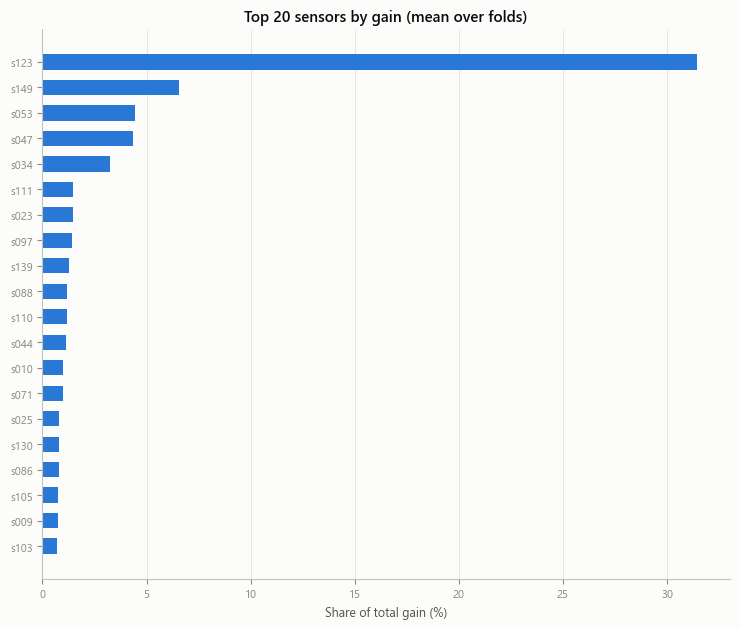

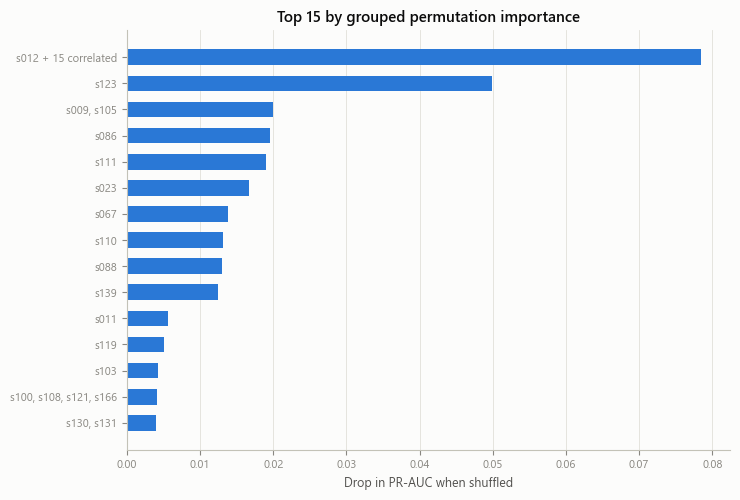

In [8]:
lm.plot_importance_bars(builtin["gain_share_mean"] * 100, "Top 20 sensors by gain (mean over folds)",
                        "Share of total gain (%)");
lm.plot_importance_bars(perm_grouped["pr_auc_drop_mean"], "Top 15 by grouped permutation importance",
                        "Drop in PR-AUC when shuffled", top=15);

**Takeaways**

- **s123 dominates:** 31% of all gain and the largest single-sensor permutation effect. It is not part of any
  near-duplicate group.
- **Methods disagree because of redundancy** (gain vs permutation rank correlation about 0.43). For example, s047 has about 4%
  of the gain but no permutation effect on its own, because 15 near-copies cover for it.
- When shuffled together, the **s012 group** (16 sensors, including s047, s120 and s149) is the most important information
  source (PR-AUC drop about 0.079), ahead of s123 (about 0.050). The 20-sensor s008/s037-s042 group is large but not in the top 15.
- About 92 of 167 sensors show no permutation effect on their own, yet removing sensors hurt in Section 2. Permutation
  importance measures *average* ranking quality, while cost depends on a few hard failures, so "low importance" does not
  mean "safe to drop".
- The test misalignment found in the EDA hit sensors in the s012 group (s047, s120, s122), which is the most important group.

## 4. Tuning LightGBM

LightGBM is competitive (Section 1), so it is tuned with a **30-trial random search** on the shared folds. Trial 0 is the
default configuration. For each trial we record:

- OOF cost (the ranking metric);
- on how many folds it beats the default;
- the cost if the chosen threshold is **halved or doubled**. This measures robustness, which matters because test has a
  different population (EDA Section 6.6).

In [9]:
trials = lm.tune_lgbm(X, y, folds, train_df, n_trials=30, log=lambda message: None)
display(trials.head(10))
display(trials.loc[[0]])

,learning_rate,n_estimators,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,scale_pos_weight,oof_cost,fold_cost_std,folds_beating_default,cost_thr_x0.5,cost_thr_x2,threshold,tp,fp,roc_auc,pr_auc,seconds
trial,,,,,,,,,,,,,,,,,,,
10,0.0638,1200,15,150,0.6000,0.3000,0.2097,10,"70,304.7600","3,785.1318",3,"72,984.9200","79,996.5600",0.0031,330,599,0.9802,0.5170,15.1393
28,0.0105,300,63,40,0.8000,0.5000,0.1550,30,"70,346.7000","3,970.0286",4,"79,688.5800","76,273.2800",0.0622,360,956,0.9848,0.5437,9.6478
17,0.0462,500,15,40,1.0000,0.5000,0.1128,1,"71,287.1000","3,124.6894",4,"77,882.4200","73,513.7400",0.0080,345,739,0.9832,0.5329,7.6434
2,0.0945,800,63,80,1.0000,0.7000,1.0873,1,"71,330.5400","2,644.3112",4,"75,251.1200","72,628.8000",0.0007,339,676,0.9842,0.5550,21.8089
16,0.0191,1200,15,40,0.8000,0.3000,6.3646,10,"71,361.8200","3,360.2462",4,"76,526.0200","79,584.2000",0.0655,339,614,0.9846,0.5532,15.5715
18,0.0123,1200,31,80,0.8000,0.7000,1.4221,1,"71,441.9600","2,575.8841",3,"74,708.5800","79,823.6400",0.0172,339,571,0.9853,0.5546,26.4358
11,0.0158,1200,7,80,1.0000,0.9000,4.1938,10,"71,598.0600","2,646.5251",4,"75,558.3200","81,531.4600",0.2080,334,598,0.9828,0.5298,13.5152
26,0.0312,300,15,80,0.6000,0.7000,2.2500,1,"71,668.9000","3,712.6549",4,"82,039.6400","80,571.8000",0.0296,353,807,0.9844,0.5538,5.3052
5,0.0573,800,15,10,1.0000,0.5000,6.1814,30,"71,904.1000","2,671.5526",4,"77,804.9600","80,968.4800",0.0146,341,774,0.9807,0.5351,12.5137


,learning_rate,n_estimators,num_leaves,min_child_samples,subsample,colsample_bytree,reg_lambda,scale_pos_weight,oof_cost,fold_cost_std,folds_beating_default,cost_thr_x0.5,cost_thr_x2,threshold,tp,fp,roc_auc,pr_auc,seconds
trial,,,,,,,,,,,,,,,,,,,
0,0.0300,500,31,20,0.8000,0.5000,1.0000,1,"73,827.7800","3,073.7224",0,"75,837.1000","78,082.5600",0.0051,352,866,0.9852,0.5583,13.4794


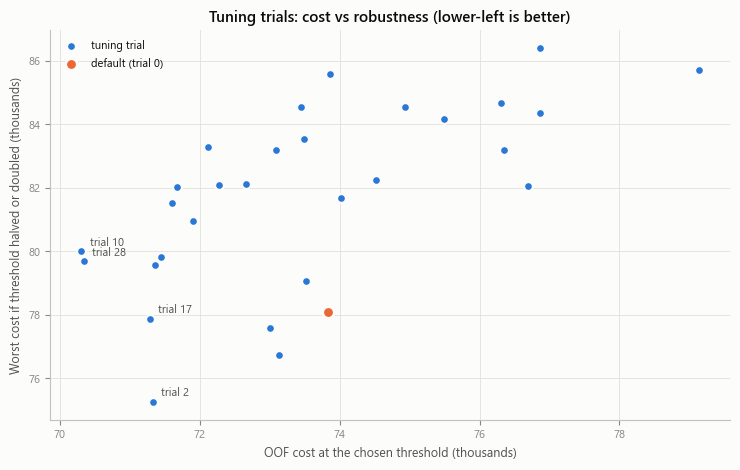

In [10]:
lm.plot_tuning(trials);

Picking the best of 30 trials on the same folds is optimistic. To check whether the differences are real, the default
and the chosen configuration are re-run with **three other random seeds**:

In [11]:
seed_table = lm.seed_stability({"default": {}, "tuned": lm.TUNED_LGBM_PARAMS}, X, y, folds, train_df)
display(seed_table)
display(pd.DataFrame({"mean": seed_table.mean(), "std": seed_table.std()}))

config,default,tuned
seed,,
7,"68,674.5000","69,788.9800"
123,"72,206.5400","68,564.9200"
2024,"69,872.3400","70,901.6600"


,mean,std
config,,
default,"70,251.1267","1,796.2283"
tuned,"69,751.8533","1,168.8123"


**Takeaways**

- At seed 42, the best trials reach about 70.3k vs 73.8k for the default. But across seeds the **default itself ranges from
  68.7k to 72.2k**: its 73.8k at seed 42 was unlucky, and **seed noise is about +/-3k**.
- **Chosen configuration (`TUNED_LGBM_PARAMS`, trial 2):** learning rate 0.0945, 800 trees, 63 leaves,
  min_child_samples 80, colsample 0.7, no class weight. Reasons:
  - lowest seed-averaged cost (69,752 vs 70,251 for the default);
  - lower variance across seeds (std 1,169 vs 1,796);
  - beats the default on 4 of 5 folds;
  - the most robust to threshold changes (worst case 75.3k when the threshold is halved or doubled, vs 78.1k for the default).
- Trial 10 had the lowest single-seed cost but is fragile: doubling its threshold raises the cost to 80.0k.
- **Tuning gives a small, more stable gain, not a large one.** On this data, CV cost differences below about 3k between
  models are not meaningful.

## 5. Final Model and Test Predictions

**Final model:** the tuned configuration averaged over **5 random seeds** (`SeedAveragedLGBM`). This reduces the seed noise
found in Section 4. The same seed-averaged model is evaluated in CV, so the threshold matches the probability scale of the
test predictions.

**Steps:**

1. Train on all 56,000 vehicles.
2. Predict the **aligned** test set (`align_test_sensors`).
3. Apply the CV threshold and the constant budget (1,187).

For diagnosis, the raw (misaligned) test file and the LR benchmark are also scored.

In [12]:
final = lm.final_report(train_df, test_df, X, y, folds,
                        cv_results={lm.LR_NAME: cv["LR benchmark (1:50)"]},
                        write_submissions=True, verbose=False)

display(lm.comparison_table(list(final["evaluations"].values())).T)
print(f"Budget for inspected vehicles: {final['budget']:,.2f}")
display(final["test_vs_cv"])
display(final["raw_vs_aligned"])
print("Submission files written to submissions/:", ", ".join(final["saved"]))

model,"LGBM tuned, 5-seed average",LR benchmark (1:50)
oof_cost,"70,153.4200","81,465.2200"
cost_per_1000_vehicles,"1,252.7396","1,454.7361"
fold_cost_mean,"14,050.9127","16,313.3233"
fold_cost_std,"3,132.5041","3,611.2066"
flagged,"1,010.0000","1,090.0000"
tp,342.0000,309.0000
fn,55.0000,88.0000
fp,668.0000,781.0000
recall,0.8615,0.7783
precision,0.3386,0.2835


Budget for inspected vehicles: 1,187.00


,threshold,flagged,test_flag_rate,cv_flag_rate,mean_probability
predictions,,,,,
lgbm_aligned,0.0010,854,0.0427,0.0180,0.0161
lgbm_raw,0.0010,890,0.0445,0.0180,0.0160
lr_aligned,0.6110,771,0.0386,0.0195,0.0602
lr_raw,0.6110,438,0.0219,0.0195,0.0300


,LGBM,LR
"Spearman(aligned, raw) probabilities",0.9676,0.5060
flagged in both,847.0000,370.0000
flagged only with aligned test,7.0000,401.0000
flagged only with raw test,43.0000,68.0000


Submission files written to submissions/: v2_lgbm_aligned.csv, v2_lgbm_raw.csv, v2_lr_aligned.csv


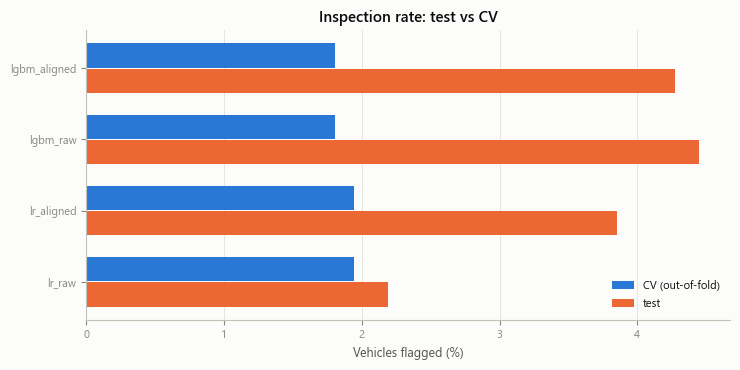

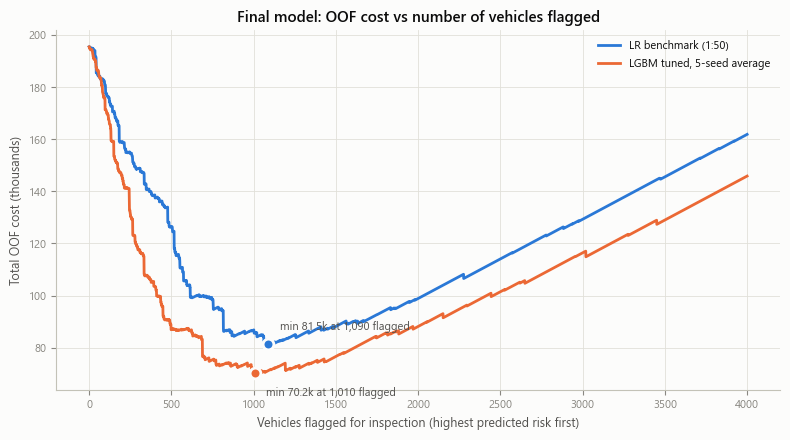

In [13]:
lm.plot_test_vs_cv(final["test_vs_cv"]);
lm.plot_cost_curves({"LR benchmark (1:50)": lm.cost_curve(cv["LR benchmark (1:50)"]["oof"], train_df),
                     "LGBM tuned, 5-seed average": lm.cost_curve(final["cv_results"][lm.FINAL_NAME]["oof"], train_df)},
                    title="Final model: OOF cost vs number of vehicles flagged");

**Takeaways**

- **Final CV result:** OOF cost **70,153**, vs 81,465 for the LR benchmark (-13.9%). It catches 342 of 397 failures (86%),
  and 34% of the flagged vehicles really fail.
- **Test is higher-risk than train:** the model flags **4.3% of test vehicles vs 1.8% in CV**. This matches EDA Section 6.6
  (test vehicles have about 3x higher predicted risk).
- **The misalignment matters a lot for LR but hardly for LightGBM.** The two models' predictions on raw vs aligned test
  correlate 0.51 (LR) and 0.97 (LightGBM), and LightGBM flags almost the same vehicles either way. LightGBM's main signal is
  spread over 16 near-duplicate sensors, so a few broken columns barely affect it.
- **Kaggle plan (submissions are unlimited):**

| File | Purpose |
|---|---|
| `v2_lgbm_aligned.csv` | Main candidate |
| `v2_lgbm_raw.csv` | Diagnostic: should score close to the aligned version |
| `v2_lr_aligned.csv` | Diagnostic: compared with V1 (84,066), shows what the alignment fix is worth for LR |

## 6. Summary

| Model (shared 5-fold CV) | OOF cost | Cost per 1,000 vehicles | ROC-AUC | Failures caught |
|---|---:|---:|---:|---:|
| LR benchmark (V1 config) | 81,465 | 1,455 | 0.938 | 309 / 397 |
| LightGBM, all features (default, seed 42) | 73,828 | 1,318 | 0.985 | 352 / 397 |
| LightGBM, selected top 30 | 74,011 | 1,322 | 0.984 | 331 / 397 |
| LightGBM, tuned (mean of 3 seeds) | 69,752 | 1,246 | - | - |
| **LightGBM, tuned, 5-seed average (final)** | **70,153** | **1,253** | **0.985** | **342 / 397** |

**Conclusions**

1. **LightGBM is clearly better than Logistic Regression** on this data: about 14% lower cost and far more stable across folds.
2. **Feature selection does not help.** LightGBM handles redundant and noisy sensors well, and removing near-duplicates
   loses information on hard cases.
3. **The most important information** is s123 and the s012 group of correlated sensors.
4. **Tuning helps only slightly.** Seed noise (about +/-3k) is as large as most tuning gains, so the final model averages 5 seeds.
5. **Test differs from train** (a higher-risk population, plus misaligned columns). CV cost is therefore an optimistic
   estimate of test cost, and the Kaggle diagnostics will show how much each issue matters.